# 03 · RFM Segmentation

**R**ecency (days since last order), **F**requency (number of orders) and
**M**onetary (net spend after returns) are scored 1–5 by quintile and mapped to
10 named segments, each with a recommended action.

*Why rule-based RFM instead of K-means?* Segments are stable, explainable to a
marketing team in one sentence, and map directly to actions. K-means clusters
change with every re-run and need to be re-interpreted each time.

Snapshot date: **2011-12-10** (the day after the last transaction).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import squarify

from src import config as C
from src import features as F
from src import io
from src import viz
from src.viz import PALETTE

viz.set_style()
t = io.load_all()
sales, returns = t["sales"], t["returns"]

## 1. Compute and score RFM

In [2]:
rfm = F.score_rfm(F.rfm_table(sales, returns, C.SCORING_DATE))
print(f"{len(rfm):,} customers scored")
rfm.describe()[["recency_days", "frequency", "monetary"]].round(1)

5,852 customers scored


,recency_days,frequency,monetary
count,5852.0,5852.0,5852.0
mean,199.7,6.3,2795.9
std,208.5,12.7,13825.2
min,0.0,1.0,0.0
25%,25.0,1.0,330.9
50%,95.0,3.0,840.2
75%,379.0,7.0,2172.0
max,738.0,373.0,578408.6


**Note on Monetary:** net of returns. Customer 12346 bought 74,215 units of one
item and returned all of them minutes later; gross spend would rank them as a
top customer, net spend correctly puts them near zero.

In [3]:
rfm.loc[[12346, 16446], ["frequency", "gross_sales", "returns_value", "monetary", "segment"]]

,frequency,gross_sales,returns_value,monetary,segment
customer_id,,,,,
12346,3,77352.96,77183.6,169.36,At Risk
16446,2,168472.50,168469.6,2.90,Potential Loyalists


## 2. Segment profile

In [4]:
seg = (rfm.groupby("segment")
       .agg(customers=("R", "size"), avg_recency=("recency_days", "mean"),
            avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"),
            revenue=("monetary", "sum")))
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()
seg = seg.sort_values("revenue", ascending=False)
seg.style.format({"avg_recency": "{:.0f}", "avg_frequency": "{:.1f}", "avg_monetary": "£{:,.0f}",
                  "revenue": "£{:,.0f}", "customer_share": "{:.1%}", "revenue_share": "{:.1%}"})

,customers,avg_recency,avg_frequency,avg_monetary,revenue,customer_share,revenue_share
segment,,,,,,,
Champions,828,8,19.3,"£10,353","£8,572,611",14.1%,52.4%
Loyal Customers,1153,66,9.8,"£3,935","£4,537,491",19.7%,27.7%
At Risk,758,371,3.9,"£1,264","£958,254",13.0%,5.9%
Potential Loyalists,710,25,2.6,£875,"£621,213",12.1%,3.8%
Hibernating,1511,456,1.2,£401,"£605,595",25.8%,3.7%
Can't Lose Them,72,327,16.4,"£6,648","£478,664",1.2%,2.9%
Need Attention,269,112,3.1,"£1,240","£333,429",4.6%,2.0%
About to Sleep,383,105,1.4,£523,"£200,367",6.5%,1.2%
Promising,114,38,1.0,£311,"£35,479",1.9%,0.2%


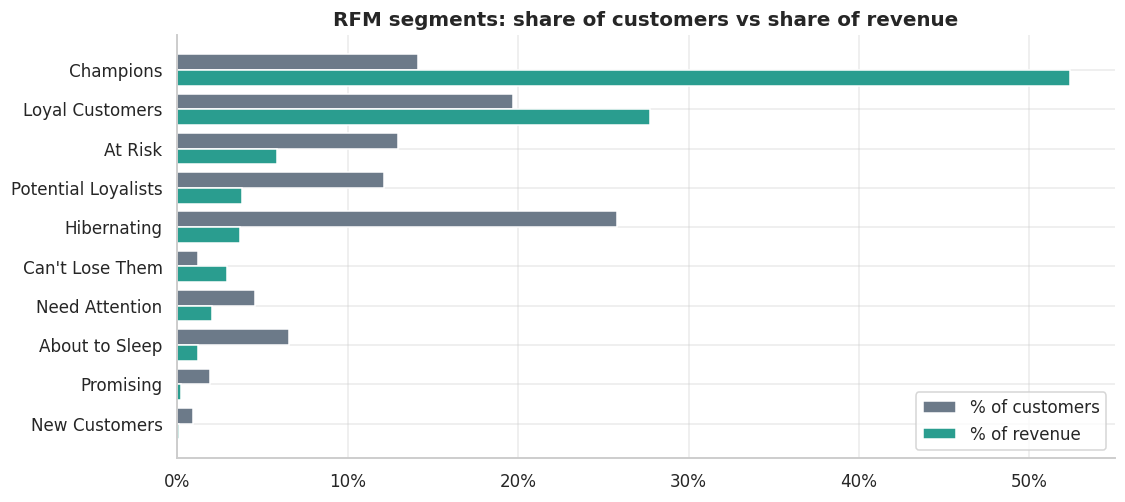

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
order = seg.index
y = np.arange(len(order))
ax.barh(y - 0.2, seg["customer_share"], 0.4, label="% of customers", color=PALETTE["slate"])
ax.barh(y + 0.2, seg["revenue_share"], 0.4, label="% of revenue", color=PALETTE["teal"])
ax.set_yticks(y, order); ax.invert_yaxis()
viz.pct_axis(ax, "x"); ax.legend(loc="lower right")
ax.set_title("RFM segments: share of customers vs share of revenue")
viz.save(fig, "10_rfm_segment_share")
plt.show()

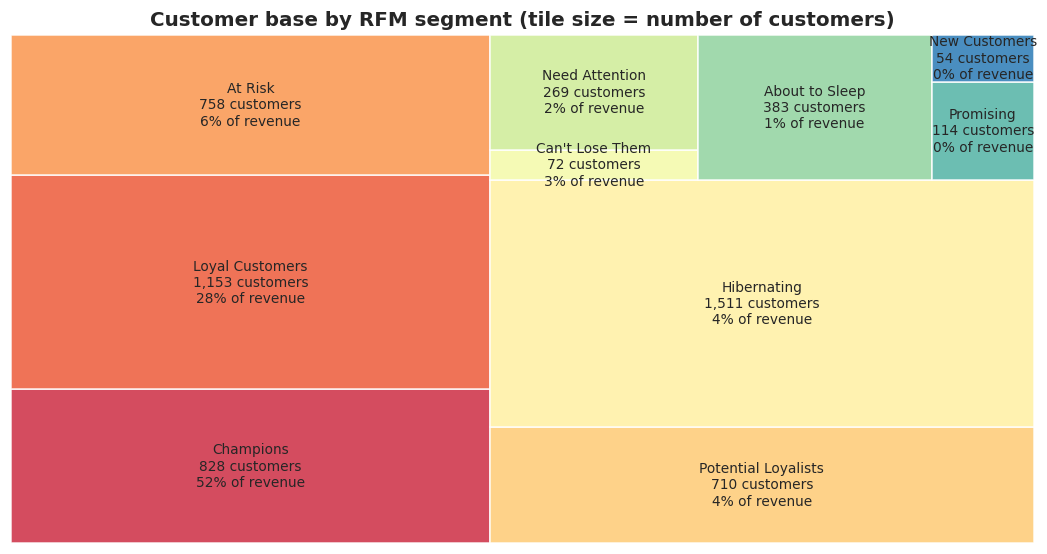

In [6]:
colors = sns.color_palette("Spectral", len(seg))
fig, ax = plt.subplots(figsize=(12, 6))
labels = [f"{s}\n{c:,} customers\n{r:.0%} of revenue" for s, c, r in zip(seg.index, seg.customers, seg.revenue_share)]
squarify.plot(sizes=seg["customers"], label=labels, color=colors, alpha=0.9, ax=ax,
              text_kwargs={"fontsize": 9})
ax.axis("off"); ax.set_title("Customer base by RFM segment (tile size = number of customers)")
viz.save(fig, "11_rfm_treemap")
plt.show()

## 3. RFM scatter
Recency vs frequency on a log scale; bubble size = net spend.

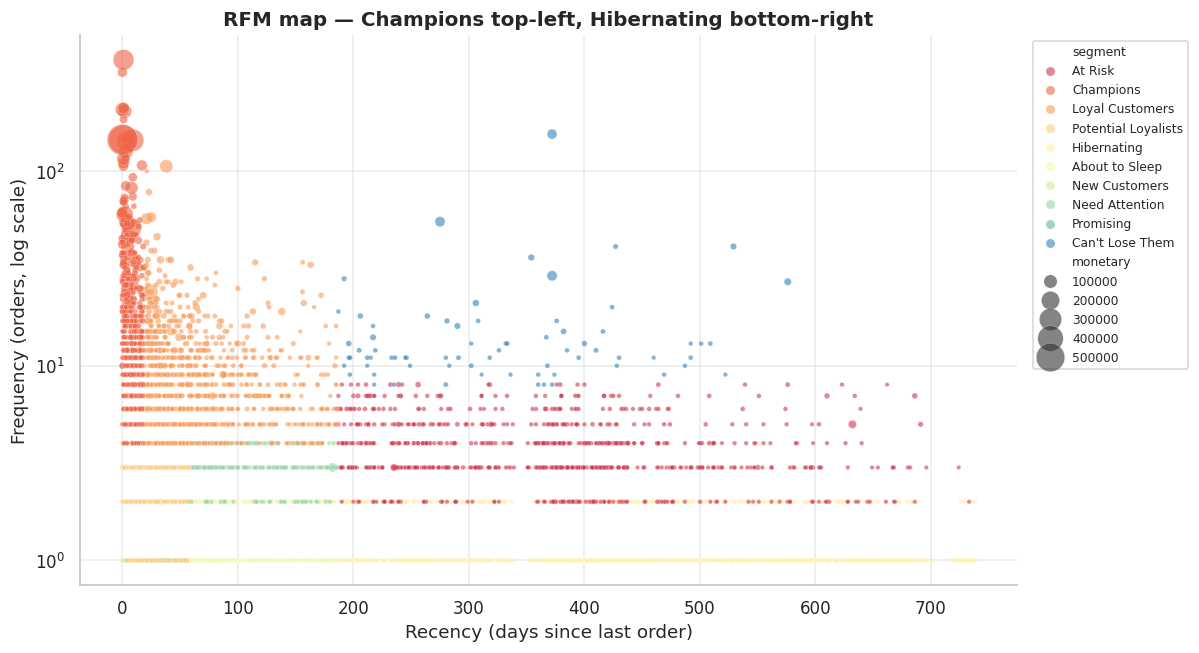

In [7]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sample = rfm[rfm["monetary"] > 0]
sns.scatterplot(data=sample, x="recency_days", y="frequency", hue="segment", size="monetary",
                sizes=(8, 400), alpha=0.6, palette="Spectral", ax=ax, legend="brief")
ax.set_yscale("log")
ax.set_xlabel("Recency (days since last order)"); ax.set_ylabel("Frequency (orders, log scale)")
ax.set_title("RFM map — Champions top-left, Hibernating bottom-right")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
viz.save(fig, "12_rfm_scatter")
plt.show()

## 4. The money question
How much historical value sits in segments that are slipping away?

In [8]:
slipping = ["At Risk", "Can't Lose Them", "About to Sleep"]
at_risk_value = seg.loc[seg.index.intersection(slipping), "revenue"].sum()
at_risk_customers = seg.loc[seg.index.intersection(slipping), "customers"].sum()
champ = seg.loc[["Champions", "Loyal Customers"]]
print(f"Champions + Loyal: {champ.customer_share.sum():.1%} of customers, {champ.revenue_share.sum():.1%} of revenue")
print(f"Slipping segments ({', '.join(slipping)}): {at_risk_customers:,} customers, "
      f"{C.CURRENCY}{at_risk_value:,.0f} lifetime net revenue ({at_risk_value / seg.revenue.sum():.1%})")

Champions + Loyal: 33.9% of customers, 80.1% of revenue
Slipping segments (At Risk, Can't Lose Them, About to Sleep): 1,213 customers, £1,637,286 lifetime net revenue (10.0%)


In [9]:
io.update_metrics({
    "champions_loyal_customer_share": float(champ.customer_share.sum()),
    "champions_loyal_revenue_share": float(champ.revenue_share.sum()),
    "slipping_customers": int(at_risk_customers),
    "slipping_lifetime_revenue": float(at_risk_value),
})
C.OUTPUTS_DIR.mkdir(exist_ok=True)
rfm.reset_index().to_csv(C.OUTPUTS_DIR / "rfm_segments.csv", index=False)
seg.reset_index().to_csv(C.OUTPUTS_DIR / "rfm_segment_summary.csv", index=False)
print("Saved outputs/rfm_segments.csv")

Saved outputs/rfm_segments.csv
